# Identificação do projeto

**Título do projeto:** Variação do preço dos combustíveis nos postos brasileiros

**Integrantes do grupo:** Eduardo Pereira, Patrick de Oliveira, Roberto Zhou, Matheus Fraiz de Camargo Antonello

**Turma:** 6º GCL1 — Sistemas de Informação (Noite) — 2026/2

**Descrição breve do problema ou contexto:** o mesmo combustível, no mesmo dia, custa valores diferentes de um posto para outro, inclusive dentro da mesma cidade. Usamos o Levantamento de Preços de Combustíveis da ANP para entender quais fatores estão associados a essa variação.

Preencha este notebook ao longo dos dois RAs. Registre decisões e interpretações em poucas frases e acrescente as células de código necessárias em cada etapa.

---

# RA1 — Data Ingestion, Cleaning and Initial Analysis

Nesta etapa, carregue, prepare e explore os dados do projeto.

## 1. Contexto e objetivo

Apresente brevemente o problema investigado e o que o grupo pretende descobrir com os dados.

**Resposta do grupo:**

O preço final dos combustíveis depende de vários fatores: imposto estadual (ICMS), custo de transporte, bandeira do posto e concorrência local. O resultado é que o consumidor paga preços bem diferentes dependendo de onde abastece.

**Pergunta central:** quais fatores estão associados à variação do preço dos combustíveis entre os postos brasileiros?

Perguntas de apoio:

1. Qual é a diferença de preço entre regiões e estados para o mesmo produto?
2. Postos sem bandeira (bandeira branca) cobram preços diferentes dos postos com bandeira?
3. Quanto o preço varia entre postos de uma mesma cidade?
4. Em quais estados o etanol compensa mais que a gasolina (regra dos 70%)?
5. Como os preços evoluíram de 2023 a 2026?

As perguntas 1 e 5 são **descritivas** e as perguntas 2, 3 e 4 são **diagnósticas**.

## 2. Fonte e ingestão dos dados

- Identifique a fonte dos dados, incluindo link ou referência de acesso.
- Descreva brevemente o dataset e o que seus registros representam.
- Explique como os dados foram carregados e implemente a ingestão.

**Resposta do grupo:**

**Fonte:** ANP — *Levantamento de Preços de Combustíveis* (Série Histórica), em
https://www.gov.br/anp/pt-br/centrais-de-conteudo/dados-abertos/serie-historica-de-precos-de-combustiveis

**O que é cada registro:** o preço de **um produto**, em **um posto**, em **uma data**. A ANP não registra todos os postos todos os dias: é uma pesquisa presencial por amostragem, então as conclusões valem para os postos pesquisados. São dados **estruturados** (CSV com 16 colunas).

**Ingestão:** a ANP publica um CSV por mês para cada grupo de produtos (gasolina/etanol, diesel/GNV e GLP). Usamos janeiro/2023 a agosto/2026: **129 arquivos**. O notebook baixa os arquivos direto da ANP, então a ingestão é reproduzível. Três cuidados foram necessários:

- de 2023 a 2025 o nome dos arquivos segue um padrão e a lista sai de um laço; em 2026 a ANP mudou o padrão e publicou um arquivo com erro de digitação (`cados-abertos-preco`), então os nomes de 2026 foram copiados da página;
- **abril/2026 não foi publicado** pela ANP (conferido em 23/09 e 14/10/2026);
- o site recusa downloads automáticos (erro 403) sem cabeçalhos de navegador.

Tudo é lido como **texto** (`dtype="string[pyarrow]"`): converter tipos é decisão de limpeza (seção 4). O tipo de texto do pyarrow ocupa cerca de 3 vezes menos memória que o padrão (1,2 GB contra 3,7 GB, medido), o que permite rodar no Colab.

In [1]:
# Bibliotecas para download, manipulação e visualização dos dados
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Configurações que deixam os resultados mais legíveis
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

print("✓ Ambiente preparado.")

✓ Ambiente preparado.


In [2]:
# Lista dos arquivos mensais da ANP
URL_BASE = "https://www.gov.br/anp/pt-br/centrais-de-conteudo/dados-abertos/arquivos/shpc/dsan"
GRUPOS = ["gasolina-etanol", "diesel-gnv", "glp"]

arquivos = []

# 2023 a 2025: o nome do arquivo segue sempre o mesmo padrão
for ano in [2023, 2024, 2025]:
    for mes in range(1, 13):
        for grupo in GRUPOS:
            arquivos.append({
                "ano": ano, "mes": mes, "grupo": grupo,
                "url": f"{URL_BASE}/{ano}/precos-{grupo}-{mes:02d}.csv",
            })

# 2026: nomes copiados da página da ANP (o padrão muda de um mês para outro)
NOMES_2026 = {
    (1, "gasolina-etanol"): "01-dados-abertos-precos-gasolina-etanol.csv",
    (1, "diesel-gnv"):      "01-dados-abertos-precos-diesel-gnv.csv",
    (1, "glp"):             "01-dados-abertos-precos-glp.csv",
    (2, "gasolina-etanol"): "02-cados-abertos-preco-gasolina-etanol.csv",  # erro de digitação da ANP
    (2, "diesel-gnv"):      "02-dados-abertos-precos-diesel-gnv.csv",
    (2, "glp"):             "02-dados-abertos-precos-glp.csv",
    (3, "gasolina-etanol"): "03-dados-abertos-precos-gasolina-etanol.csv",
    (3, "diesel-gnv"):      "03-dados-abertos-precos-diesel-gnv.csv",
    (3, "glp"):             "03-dados-abertos-precos-glp.csv",
    # abril/2026 não foi publicado
    (5, "gasolina-etanol"): "05-dados-abertos-precos-gasolina-etanol.csv",
    (5, "diesel-gnv"):      "05-dados-abertos-precos-diesel-gnv.csv",
    (5, "glp"):             "05-dados-abertos-precos-glp.csv",
    (6, "gasolina-etanol"): "06-dados-abertos-precos-2026-06-gasolina-etanol.csv",
    (6, "diesel-gnv"):      "06-dados-abertos-precos-2026-06-diesel-gnv.csv",
    (6, "glp"):             "06-dados-abertos-precos-2026-06-glp.csv",
    (7, "gasolina-etanol"): "07-dados-abertos-precos-gasolina-etanol.csv",
    (7, "diesel-gnv"):      "07-dados-abertos-precos-diesel-gnv.csv",
    (7, "glp"):             "07-dados-abertos-precos-glp.csv",
    (8, "gasolina-etanol"): "08-dados-abertos-precos-2026-08-gasolina-etanol.csv",
    (8, "diesel-gnv"):      "08-dados-abertos-precos-2026-08-diesel-gnv.csv",
    (8, "glp"):             "08-dados-abertos-precos-2026-08-glp.csv",
}
for (mes, grupo), nome in NOMES_2026.items():
    arquivos.append({"ano": 2026, "mes": mes, "grupo": grupo, "url": f"{URL_BASE}/2026/{nome}"})

MESES_AUSENTES = [(2026, 4)]

print(f"Arquivos na lista:        {len(arquivos)}")
print(f"Meses com dados:          {len(arquivos) // len(GRUPOS)}")
print(f"Meses ausentes na origem: {MESES_AUSENTES}")

Arquivos na lista:        129
Meses com dados:          43
Meses ausentes na origem: [(2026, 4)]


In [3]:
# Download para data/raw/ (arquivos já baixados não são baixados de novo)
PASTA_RAW = os.path.join("data", "raw")
os.makedirs(PASTA_RAW, exist_ok=True)

# Sem esses cabeçalhos o site da ANP responde com erro 403
CABECALHOS = {
    "User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                   "(KHTML, like Gecko) Chrome/140.0 Safari/537.36"),
    "Referer": ("https://www.gov.br/anp/pt-br/centrais-de-conteudo/dados-abertos/"
                "serie-historica-de-precos-de-combustiveis"),
}

for item in arquivos:
    item["arquivo"] = f"{item['grupo']}_{item['ano']}-{item['mes']:02d}.csv"
    caminho = os.path.join(PASTA_RAW, item["arquivo"])

    if os.path.exists(caminho):
        item["status"] = "já existia"
        continue

    resposta = requests.get(item["url"], headers=CABECALHOS, timeout=180)
    if resposta.status_code == 200:
        with open(caminho, "wb") as f:
            f.write(resposta.content)
        item["status"] = "baixado"
    else:
        item["status"] = f"erro {resposta.status_code}"

controle = pd.DataFrame(arquivos)
erros = controle[controle["status"].str.startswith("erro")]
assert erros.empty, f"Falha ao baixar {len(erros)} arquivo(s):\n{erros[['arquivo', 'status']]}"

tamanho_mb = sum(os.path.getsize(os.path.join(PASTA_RAW, a)) for a in controle["arquivo"]) / 1e6
print("RESULTADO DO DOWNLOAD")
print("─" * 50)
print(controle["status"].value_counts().to_string())
print(f"✓ {len(controle)} arquivos disponíveis em data/raw/ ({tamanho_mb:,.0f} MB)")

RESULTADO DO DOWNLOAD
──────────────────────────────────────────────────
status
já existia    129
✓ 129 arquivos disponíveis em data/raw/ (633 MB)


In [4]:
# Leitura e junção dos 129 arquivos em um único DataFrame
COLUNAS_ESPERADAS = [
    "Regiao - Sigla", "Estado - Sigla", "Municipio", "Revenda", "CNPJ da Revenda",
    "Nome da Rua", "Numero Rua", "Complemento", "Bairro", "Cep", "Produto",
    "Data da Coleta", "Valor de Venda", "Valor de Compra", "Unidade de Medida", "Bandeira",
]

partes = []
for item in arquivos:
    df = pd.read_csv(
        os.path.join(PASTA_RAW, item["arquivo"]),
        sep=";",                    # separador ponto e vírgula
        encoding="utf-8-sig",       # os arquivos começam com BOM
        dtype="string[pyarrow]",    # tudo como texto; tipos são decididos na limpeza
        keep_default_na=False,      # não transforma textos como "NA" em ausente...
        na_values=[""],             # ...apenas a célula realmente vazia
    )
    item["linhas"] = len(df)
    item["mesmo_cabecalho"] = list(df.columns) == COLUNAS_ESPERADAS
    df["arquivo_origem"] = item["arquivo"]
    partes.append(df)

df_original = pd.concat(partes, ignore_index=True)
controle = pd.DataFrame(arquivos)

# Controle da ingestão: qual arquivo veio de qual URL e com quantas linhas
controle[["ano", "mes", "grupo", "arquivo", "url", "linhas"]].to_csv(
    os.path.join("data", "controle_ingestao.csv"), index=False
)

print("✓ Dados carregados com sucesso!")
print(f"Arquivos lidos:                   {len(partes)}")
print(f"Arquivos com cabeçalho diferente: {(~controle['mesmo_cabecalho']).sum()}")
print(f"Shape: {df_original.shape[0]:,} linhas × {df_original.shape[1]} colunas")

registros_por_ano = controle.pivot_table(index="ano", columns="grupo", values="linhas", aggfunc="sum")
registros_por_ano["total"] = registros_por_ano.sum(axis=1)
print("\nRegistros por ano e grupo:")
display(registros_por_ano.style.format("{:,.0f}"))

✓ Dados carregados com sucesso!
Arquivos lidos:                   129
Arquivos com cabeçalho diferente: 0
Shape: 3,717,753 linhas × 17 colunas

Registros por ano e grupo:


grupo,diesel-gnv,gasolina-etanol,glp,total
ano,,,,
2023,"294,565","610,912","228,302","1,133,779"
2024,"287,792","610,744","160,496","1,059,032"
2025,"248,742","555,836","125,203","929,781"
2026,"156,150","344,010","95,001","595,161"


In [5]:
# O que cada coluna representa
dicionario = pd.DataFrame({
    "coluna": COLUNAS_ESPERADAS,
    "significado": [
        "Região do país (N, NE, CO, SE, S)", "Unidade da federação", "Município do posto",
        "Nome (razão social) do posto", "CNPJ do posto", "Endereço: rua", "Endereço: número",
        "Endereço: complemento", "Endereço: bairro", "Endereço: CEP", "Combustível pesquisado",
        "Data em que o preço foi coletado", "Preço cobrado do consumidor",
        "Preço pago pelo posto à distribuidora", "Unidade em que o preço está expresso",
        "Distribuidora do posto (BRANCA = sem bandeira)",
    ],
    "usada nas perguntas?": [
        "sim", "sim", "sim", "não", "sim (identifica o posto)", "não", "não", "não", "não",
        "talvez", "sim", "sim", "sim (variável principal)", "seria, se tivesse dados", "sim", "sim",
    ],
})
display(dicionario.style.hide(axis="index"))

coluna,significado,usada nas perguntas?
Regiao - Sigla,"Região do país (N, NE, CO, SE, S)",sim
Estado - Sigla,Unidade da federação,sim
Municipio,Município do posto,sim
Revenda,Nome (razão social) do posto,não
CNPJ da Revenda,CNPJ do posto,sim (identifica o posto)
Nome da Rua,Endereço: rua,não
Numero Rua,Endereço: número,não
Complemento,Endereço: complemento,não
Bairro,Endereço: bairro,não
Cep,Endereço: CEP,talvez


## 3. Exploração inicial dos dados

Investigue a quantidade de registros e colunas, os tipos de dados, os valores ausentes e outras características relevantes da base.

In [6]:
print("VISÃO GERAL DA BASE ORIGINAL")
print("─" * 50)
print(f"Linhas:  {df_original.shape[0]:,}")
print(f"Colunas: {df_original.shape[1]}")

# Tipos que o pandas escolheria sozinho, lendo um arquivo sem configuração extra
amostra_padrao = pd.read_csv(os.path.join(PASTA_RAW, arquivos[0]["arquivo"]), sep=";")
tipos = pd.DataFrame({
    "tipo inferido pelo pandas": amostra_padrao.dtypes.astype(str),
    "exemplo de valor": amostra_padrao.iloc[0].astype(str),
})
print(f"\nTipos inferidos ao ler {arquivos[0]['arquivo']} sem configurar nada:")
display(tipos)

VISÃO GERAL DA BASE ORIGINAL
──────────────────────────────────────────────────
Linhas:  3,717,753
Colunas: 17



Tipos inferidos ao ler gasolina-etanol_2023-01.csv sem configurar nada:


,tipo inferido pelo pandas,exemplo de valor
Regiao - Sigla,str,NE
Estado - Sigla,str,AL
Municipio,str,ARAPIRACA
Revenda,str,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...
CNPJ da Revenda,str,02.817.655/0001-82
Nome da Rua,str,RODOVIA AL 220 - KM 06
Numero Rua,str,S/N
Complemento,str,NaN
Bairro,str,PLANALTO
Cep,str,57308-000


,quantidade ausente,percentual ausente (%)
Valor de Compra,"3,717,753",100.00%
Complemento,"2,850,289",76.67%
Bairro,"8,352",0.22%
Numero Rua,"3,236",0.09%
Regiao - Sigla,"2,713",0.07%
CNPJ da Revenda,"2,713",0.07%
Revenda,"2,713",0.07%
Municipio,"2,713",0.07%
Estado - Sigla,"2,713",0.07%
Nome da Rua,"2,713",0.07%


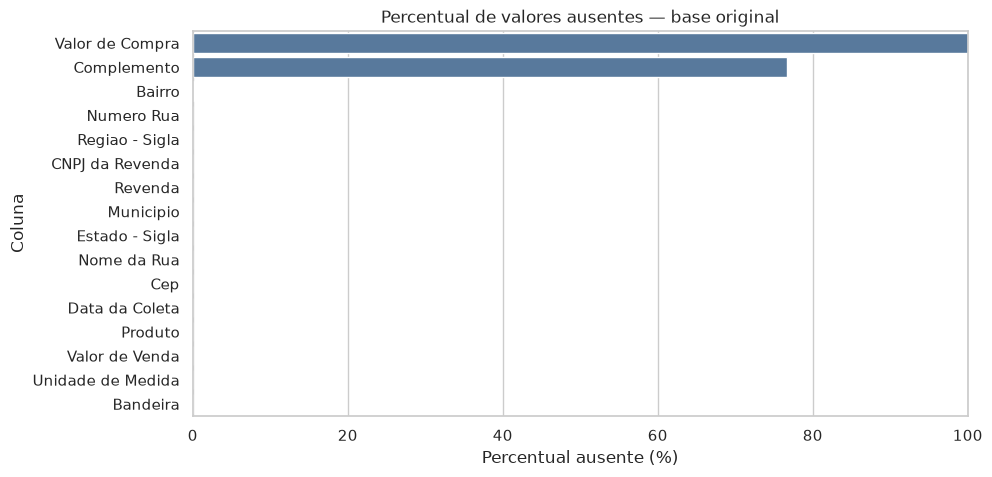

In [7]:
# Valores ausentes: quantidade e percentual por coluna
ausencias = pd.DataFrame({
    "quantidade ausente": df_original.isna().sum(),
    "percentual ausente (%)": df_original.isna().mean().mul(100),
}).sort_values("percentual ausente (%)", ascending=False)
ausencias = ausencias[ausencias["quantidade ausente"] > 0]

display(ausencias.style.format({"quantidade ausente": "{:,}", "percentual ausente (%)": "{:.2f}%"}))

plt.figure(figsize=(10, 5))
sns.barplot(data=ausencias.reset_index(), x="percentual ausente (%)", y="index", color="#4C78A8")
plt.title("Percentual de valores ausentes — base original")
plt.xlabel("Percentual ausente (%)")
plt.ylabel("Coluna")
plt.xlim(0, 100)
plt.show()

In [8]:
# Valores distintos e linhas repetidas
distintos = df_original[COLUNAS_ESPERADAS].nunique().rename("valores distintos").to_frame()
display(distintos.style.format("{:,}"))

linhas_iguais = int(df_original.duplicated(subset=COLUNAS_ESPERADAS).sum())
print(f"Linhas iguais a outra (16 colunas): {linhas_iguais:,}")

,valores distintos
Regiao - Sigla,5
Estado - Sigla,27
Municipio,471
Revenda,"20,592"
CNPJ da Revenda,"21,645"
Nome da Rua,"13,865"
Numero Rua,"5,033"
Complemento,"3,982"
Bairro,"7,987"
Cep,"15,436"


Linhas iguais a outra (16 colunas): 2,728


In [9]:
# Produtos, unidades e faixa de preço (conversão temporária, só para explorar)
preco_tmp = pd.to_numeric(df_original["Valor de Venda"].str.replace(",", ".", regex=False), errors="coerce")

faixa_preco = (
    preco_tmp.groupby([df_original["Produto"], df_original["Unidade de Medida"]])
    .agg(registros="count", minimo="min", mediana="median", maximo="max")
    .reset_index()
)
display(faixa_preco.style.format({"registros": "{:,}", "minimo": "{:.2f}", "mediana": "{:.2f}", "maximo": "{:.2f}"})
        .hide(axis="index"))
del preco_tmp

Produto,Unidade de Medida,registros,minimo,mediana,maximo
DIESEL,R$ / litro,"349,124",3.97,5.99,9.45
DIESEL S10,R$ / litro,"570,952",4.19,6.09,9.99
ETANOL,R$ / litro,"684,106",2.63,4.19,7.44
GASOLINA,R$ / litro,"808,714",4.09,5.99,9.79
GASOLINA ADITIVADA,R$ / litro,"628,682",3.47,6.19,9.89
GLP,R$ / 13 kg,"607,766",65.00,105.00,170.00
GNV,R$ / m³,"65,696",2.39,4.69,6.89


**Resposta do grupo:**

- A base tem **3.717.753 linhas e 17 colunas** (16 da ANP + a coluna `arquivo_origem`, criada na ingestão). Os 129 arquivos têm exatamente o mesmo cabeçalho.
- Lidos sem configuração, **preço e data viram texto**: o preço usa vírgula decimal e a data está em `dd/mm/aaaa`.
- `Valor de Compra` está **100% vazia** e `Complemento`, 77% vazia. Quase todas as outras colunas têm **exatamente 2.713 ausentes**, o que indica linhas inteiras vazias. Elas também explicam boa parte das 2.728 linhas repetidas, já que são todas iguais entre si (investigado na seção 4).
- Há 21.645 postos (CNPJ), 471 municípios, as 27 UFs e 7 produtos.
- A coluna de preço mistura **três unidades**: R\$/litro, R\$/m³ (GNV) e R\$/13 kg (botijão de GLP, que custa dezenas de vezes mais). Cada produto tem uma única unidade.

## 4. Limpeza e preparação dos dados

Realize a limpeza necessária ao projeto. Verifique valores ausentes, duplicados e inconsistências e trate os problemas encontrados, quando necessário.

Seguimos a sequência **Inspecionar → Decidir → Transformar → Validar**. Primeiro investigamos cada suspeita da exploração; depois registramos as decisões; só então tratamos e conferimos o resultado.

### 4.1 Problemas encontrados

As verificações usam uma cópia sem as linhas vazias (`df_inspecao`) e conversões **temporárias**, para não alterar `df_original`.

In [10]:
# Linhas em que as 16 colunas estão vazias
linha_vazia = df_original[COLUNAS_ESPERADAS].isna().all(axis=1)
df_inspecao = df_original[~linha_vazia].copy()

# Conversões temporárias, apenas para inspeção
preco = pd.to_numeric(df_inspecao["Valor de Venda"].str.replace(",", ".", regex=False), errors="coerce")
data = pd.to_datetime(df_inspecao["Data da Coleta"], format="%d/%m/%Y", errors="coerce")
cnpj = df_inspecao["CNPJ da Revenda"].str.replace(r"\D", "", regex=True)
mes_arquivo = df_inspecao["arquivo_origem"].str[-11:-4]   # "2025-06" a partir de "glp_2025-06.csv"
grupo = df_inspecao["arquivo_origem"].str.split("_").str[0]

print("LINHAS VAZIAS")
print("─" * 50)
print(f"Total: {linha_vazia.sum():,}")
display(df_original.loc[linha_vazia, "arquivo_origem"].value_counts().to_frame("linhas vazias"))

with open(os.path.join(PASTA_RAW, "diesel-gnv_2023-01.csv"), encoding="utf-8-sig") as f:
    linhas_arquivo = f.read().splitlines()
primeira_vazia = next(i for i, linha in enumerate(linhas_arquivo) if linha.strip(";") == "")
print(f"Em diesel-gnv_2023-01.csv, as linhas vazias vão da linha {primeira_vazia + 1:,} até a última ({len(linhas_arquivo):,}).")
print(f"Conteúdo de uma delas: {linhas_arquivo[-1]!r}")

LINHAS VAZIAS
──────────────────────────────────────────────────
Total: 2,713


,linhas vazias
arquivo_origem,
diesel-gnv_2023-01.csv,1477
glp_2023-01.csv,1236


Em diesel-gnv_2023-01.csv, as linhas vazias vão da linha 21,963 até a última (23,439).
Conteúdo de uma delas: ';;;;;;;;;;;;;;;'


In [11]:
# Duplicatas e chave natural: um posto, um produto e uma data deveriam ter um único preço
duplicada = df_inspecao.duplicated(subset=COLUNAS_ESPERADAS)

chave = pd.DataFrame({"cnpj": cnpj, "produto": df_inspecao["Produto"], "data": df_inspecao["Data da Coleta"]})
conflito = chave.duplicated(keep=False) & ~df_inspecao.duplicated(subset=COLUNAS_ESPERADAS, keep=False)

print("DUPLICATAS")
print("─" * 50)
print(f"Linhas idênticas a outra (excedentes):          {duplicada.sum():,}")
print(f"Mesmo posto, produto e dia com preço diferente: {conflito.sum():,} linhas")
display(df_inspecao.loc[conflito, ["Municipio", "CNPJ da Revenda", "Produto", "Data da Coleta", "Valor de Venda"]]
        .sort_values(["Produto", "Data da Coleta"]))

DUPLICATAS
──────────────────────────────────────────────────
Linhas idênticas a outra (excedentes):          16
Mesmo posto, produto e dia com preço diferente: 8 linhas


,Municipio,CNPJ da Revenda,Produto,Data da Coleta,Valor de Venda
1654536,TAUBATE,00.008.226/0001-39,GASOLINA,10/06/2024,"5,48"
1654538,TAUBATE,00.008.226/0001-39,GASOLINA,10/06/2024,"5,65"
1661787,TAUBATE,00.008.226/0001-39,GASOLINA,12/06/2024,"5,48"
1661789,TAUBATE,00.008.226/0001-39,GASOLINA,12/06/2024,"5,65"
1654537,TAUBATE,00.008.226/0001-39,GASOLINA ADITIVADA,10/06/2024,"5,59"
1654539,TAUBATE,00.008.226/0001-39,GASOLINA ADITIVADA,10/06/2024,"5,77"
1661788,TAUBATE,00.008.226/0001-39,GASOLINA ADITIVADA,12/06/2024,"5,59"
1661790,TAUBATE,00.008.226/0001-39,GASOLINA ADITIVADA,12/06/2024,"5,77"


In [12]:
# Preço e data: tipos e formatos
print("PREÇO")
print("─" * 50)
print(f"Escritos com vírgula decimal:               {df_inspecao['Valor de Venda'].str.contains(',', regex=False).sum():,}")
print(f"Que não viram número trocando vírgula/ponto: {preco.isna().sum():,}")
print(f"Menores ou iguais a zero:                   {(preco <= 0).sum():,}")
print(f"Unidades de medida na mesma coluna:         {df_inspecao['Unidade de Medida'].nunique()}")
print(f"Média geral da coluna (sem separar unidade): R$ {preco.mean():.2f}  ← número sem sentido")

print("\nDATA DA COLETA")
print("─" * 50)
exemplo = "02/06/2025"
print(f"'{exemplo}' sem informar o formato:    {pd.to_datetime(exemplo).date()}   ← fevereiro (errado)")
print(f"'{exemplo}' com format='%d/%m/%Y': {pd.to_datetime(exemplo, format='%d/%m/%Y').date()}   ← junho (certo)")
print(f"Datas fora do formato dd/mm/aaaa:   {data.isna().sum():,}")
print(f"Datas fora do mês do arquivo:       {(data.dt.strftime('%Y-%m') != mes_arquivo).sum():,}")

print("\nCNPJ")
print("─" * 50)
print(f"Exemplo como veio no arquivo:       {df_inspecao['CNPJ da Revenda'].iloc[0]!r}")
print(f"Com espaço no início ou no fim:     {(df_inspecao['CNPJ da Revenda'] != df_inspecao['CNPJ da Revenda'].str.strip()).sum():,}")
print(f"Com 14 dígitos, tirando pontuação:  {(cnpj.str.len() == 14).sum():,} de {len(cnpj):,}")

PREÇO
──────────────────────────────────────────────────
Escritos com vírgula decimal:               3,425,701
Que não viram número trocando vírgula/ponto: 0
Menores ou iguais a zero:                   0
Unidades de medida na mesma coluna:         3
Média geral da coluna (sem separar unidade): R$ 22.23  ← número sem sentido

DATA DA COLETA
──────────────────────────────────────────────────
'02/06/2025' sem informar o formato:    2025-02-06   ← fevereiro (errado)
'02/06/2025' com format='%d/%m/%Y': 2025-06-02   ← junho (certo)
Datas fora do formato dd/mm/aaaa:   0


Datas fora do mês do arquivo:       0

CNPJ
──────────────────────────────────────────────────
Exemplo como veio no arquivo:       ' 02.817.655/0001-82'
Com espaço no início ou no fim:     3,715,040
Com 14 dígitos, tirando pontuação:  3,715,040 de 3,715,040


In [13]:
# Bandeira: mesma empresa com nomes diferentes ao longo do tempo
periodo_bandeira = mes_arquivo.groupby(df_inspecao["Bandeira"]).agg(registros="size", primeiro_mes="min", ultimo_mes="max")
print("BANDEIRA — NOMES QUE SE SUCEDEM NO TEMPO")
display(periodo_bandeira.loc[["VIBRA ENERGIA", "VIBRA", "ALESAT", "ALE", "SUPERGASBRAS", "SUPERGASBRAS ENERGIA"]]
        .style.format({"registros": "{:,}"}))

# Um posto pode ter duas bandeiras no mesmo dia?
bandeiras_no_dia = df_inspecao["Bandeira"].groupby([cnpj, df_inspecao["Data da Coleta"]]).nunique()
nao_glp = grupo != "glp"
sem_glp = df_inspecao.loc[nao_glp, "Bandeira"].groupby([cnpj[nao_glp], df_inspecao.loc[nao_glp, "Data da Coleta"]]).nunique()
print(f"Posto-dia com mais de uma bandeira (todos os produtos): {(bandeiras_no_dia > 1).sum():,}")
print(f"Posto-dia com mais de uma bandeira (sem o GLP):         {(sem_glp > 1).sum():,}")

BANDEIRA — NOMES QUE SE SUCEDEM NO TEMPO


,registros,primeiro_mes,ultimo_mes
Bandeira,,,
VIBRA ENERGIA,"99,128",2023-01,2023-07
VIBRA,"558,225",2023-07,2026-08
ALESAT,"47,102",2023-01,2024-05
ALE,"52,182",2024-05,2026-08
SUPERGASBRAS,28,2023-01,2023-09
SUPERGASBRAS ENERGIA,"88,880",2023-01,2026-08


Posto-dia com mais de uma bandeira (todos os produtos): 22,376
Posto-dia com mais de uma bandeira (sem o GLP):         0


**Bandeira:** `VIBRA ENERGIA` some em julho/2023 quando `VIBRA` aparece; `ALESAT` some em maio/2024 quando `ALE` aparece; `SUPERGASBRAS` e `SUPERGASBRAS ENERGIA` são a mesma distribuidora. Os 22 mil casos de "posto com duas bandeiras no mesmo dia" desaparecem sem o GLP: no GLP a coluna `Bandeira` é a **marca do botijão** (Liquigás, Ultragaz…), e não a distribuidora do posto. Não é erro, é diferença de significado.

In [14]:
# Colunas pouco úteis e inconsistências que os dados não permitem resolver
numero = df_inspecao["Numero Rua"].dropna().str.strip()
nao_numerico = numero[~numero.str.fullmatch(r"\d+")]
nomes_por_posto = df_inspecao["Revenda"].groupby(cnpj).nunique()
municipios_por_posto = df_inspecao["Municipio"].groupby(cnpj).nunique()
ufs_por_posto = df_inspecao["Estado - Sigla"].groupby(cnpj).nunique()

print("COLUNAS POUCO ÚTEIS")
print("─" * 50)
print(f"Valor de Compra vazia:          {df_inspecao['Valor de Compra'].isna().mean():.0%}")
print(f"Complemento vazio:              {df_inspecao['Complemento'].isna().mean():.0%}")
print(f"Numero Rua que não é número:    {len(nao_numerico):,}  ex: {nao_numerico.value_counts().index[:5].tolist()}")
print(f"Postos com mais de um nome:     {(nomes_por_posto > 1).sum():,} de {len(nomes_por_posto):,}")

# Gasolina aditivada deveria custar o mesmo ou mais que a comum no mesmo posto e dia
base_preco = pd.DataFrame({
    "cnpj": cnpj, "data": df_inspecao["Data da Coleta"], "mes": mes_arquivo,
    "uf": df_inspecao["Estado - Sigla"], "municipio": df_inspecao["Municipio"],
    "produto": df_inspecao["Produto"], "preco": preco,
})
gasolinas = (
    base_preco[base_preco["produto"].isin(["GASOLINA", "GASOLINA ADITIVADA"])]
    .pivot_table(index=["cnpj", "data", "mes"], columns="produto", values="preco", aggfunc="first")
    .dropna()
)
invertidos = gasolinas[gasolinas["GASOLINA ADITIVADA"] < gasolinas["GASOLINA"]]

# Preços muito distantes dos outros postos do mesmo produto, estado e mês (regra 3 × IQR)
precos_do_grupo = base_preco.groupby(["produto", "uf", "mes"])["preco"]
q1 = precos_do_grupo.transform(lambda s: s.quantile(0.25))
q3 = precos_do_grupo.transform(lambda s: s.quantile(0.75))
outlier = (base_preco["preco"] < q1 - 3 * (q3 - q1)) | (base_preco["preco"] > q3 + 3 * (q3 - q1))

print("\nINCONSISTÊNCIAS SEM COMO CORRIGIR")
print("─" * 50)
print(f"Postos em mais de um município: {(municipios_por_posto > 1).sum()} (em mais de uma UF: {(ufs_por_posto > 1).sum()})")
print(f"Aditivada mais barata que a comum: {len(invertidos)} de {len(gasolinas):,} posto-dia "
      f"({invertidos.index.get_level_values('mes').isin(['2023-01', '2023-02']).sum()} em jan-fev/2023)")
print(f"Preços fora de 3 × IQR:          {outlier.sum():,} ({outlier.mean():.2%})")
display(invertidos.assign(diferenca=lambda t: t["GASOLINA"] - t["GASOLINA ADITIVADA"])
        .sort_values("diferenca", ascending=False).head(3))

COLUNAS POUCO ÚTEIS
──────────────────────────────────────────────────
Valor de Compra vazia:          100%
Complemento vazio:              77%
Numero Rua que não é número:    496,622  ex: ['S/N', 'SN', 'S N', 'S/Nº', 'S/N.']
Postos com mais de um nome:     1,598 de 21,645



INCONSISTÊNCIAS SEM COMO CORRIGIR
──────────────────────────────────────────────────
Postos em mais de um município: 33 (em mais de uma UF: 0)
Aditivada mais barata que a comum: 105 de 608,980 posto-dia (63 em jan-fev/2023)
Preços fora de 3 × IQR:          28,391 (0.76%)


,,produto,GASOLINA,GASOLINA ADITIVADA,diferenca
cnpj,data,mes,,,
00599333000189,30/01/2023,2023-01,8.19,5.29,2.90
12811039000178,25/01/2023,2023-01,5.37,3.57,1.80
07026084000181,30/01/2023,2023-01,4.87,3.47,1.40


In [15]:
# Verificações que não encontraram problema também são resultado
regioes_por_uf = df_inspecao["Regiao - Sigla"].groupby(df_inspecao["Estado - Sigla"]).nunique()
ufs_por_mes = df_inspecao["Estado - Sigla"].groupby(mes_arquivo).nunique()
unidades_por_produto = df_inspecao["Unidade de Medida"].groupby(df_inspecao["Produto"]).nunique()
ufs_por_municipio = df_inspecao["Estado - Sigla"].groupby(df_inspecao["Municipio"]).nunique()

sem_problema = pd.DataFrame({
    "verificação": [
        "Arquivos com cabeçalho diferente", "Preços que não viram número", "Preços menores ou iguais a zero",
        "Datas fora do formato dd/mm/aaaa", "Datas fora do mês do arquivo",
        "Produtos com mais de uma unidade", "CNPJs sem 14 dígitos", "CEPs fora do formato 00000-000",
        "Estados em mais de uma região", "Meses sem as 27 UFs", "Postos que mudam de estado",
        "Textos como 'NA' ou 'NULL' no lugar de vazio",
    ],
    "resultado": [
        int((~controle["mesmo_cabecalho"]).sum()), int(preco.isna().sum()), int((preco <= 0).sum()),
        int(data.isna().sum()), int((data.dt.strftime("%Y-%m") != mes_arquivo).sum()),
        int((unidades_por_produto > 1).sum()), int((cnpj.str.len() != 14).sum()),
        int((~df_inspecao["Cep"].str.fullmatch(r"\d{5}-\d{3}")).sum()),
        int((regioes_por_uf > 1).sum()), int((ufs_por_mes < 27).sum()), int((ufs_por_posto > 1).sum()),
        int(df_inspecao[COLUNAS_ESPERADAS].isin(["NA", "N/A", "NULL", "null", "nan"]).sum().sum()),
    ],
})
display(sem_problema.style.hide(axis="index"))
print(f"Município com o mesmo nome em mais de um estado: {ufs_por_municipio[ufs_por_municipio > 1].index.tolist()}")
print("→ município sozinho não identifica uma cidade; usamos sempre (estado, município).")

# Liberamos a memória das cópias usadas só na inspeção
del df_inspecao, base_preco, chave, preco, data, cnpj, mes_arquivo, grupo

verificação,resultado
Arquivos com cabeçalho diferente,0
Preços que não viram número,0
Preços menores ou iguais a zero,0
Datas fora do formato dd/mm/aaaa,0
Datas fora do mês do arquivo,0
Produtos com mais de uma unidade,0
CNPJs sem 14 dígitos,0
CEPs fora do formato 00000-000,0
Estados em mais de uma região,0
Meses sem as 27 UFs,0


Município com o mesmo nome em mais de um estado: ['VALENCA']
→ município sozinho não identifica uma cidade; usamos sempre (estado, município).


### 4.2 Decisões

Antes de transformar, registramos cada decisão e sua justificativa. Algumas são de **não fazer nada**, porque o problema não pode ser resolvido com os dados disponíveis ou porque mexer nos valores distorceria o que queremos estudar.

In [16]:
decisoes = pd.DataFrame({
    "problema": [
        "Linhas totalmente vazias", "Linhas duplicadas", "Mesmo posto, produto e dia com dois preços",
        "Preço como texto com vírgula", "Três unidades de medida no preço", "Data como texto (dd/mm/aaaa)",
        "CNPJ com espaço e pontuação", "Mesma bandeira com nomes diferentes", "Bandeira com outro significado no GLP",
        "Valor de Compra sempre vazia", "Endereço e nome do posto", "Nomes de coluna com espaço e hífen",
        "Posto em mais de um município", "Aditivada mais barata que a comum", "Preços distantes da maioria",
    ],
    "decisão": [
        "Remover", "Manter uma ocorrência", "Remover as 8 linhas",
        "Converter para número", "Não converter; manter a coluna de unidade", "Converter informando o formato",
        "Manter só os 14 dígitos", "Unificar no nome mais recente", "Manter",
        "Remover a coluna", "Remover as colunas (exceto CEP)", "Renomear (minúsculas, sem espaço)",
        "Manter", "Manter", "Manter",
    ],
    "justificativa": [
        "Não têm nenhuma informação",
        "São linhas completamente iguais",
        "Não há como saber qual preço foi praticado; são 8 em 3,7 milhões",
        "Cálculos exigem tipo numérico",
        "Converter botijão e m³ para litro exigiria dados que a base não tem; basta comparar dentro do mesmo produto",
        "Sem o formato, o pandas pode trocar dia e mês sem avisar",
        "O CNPJ identifica o posto e precisa de uma forma única",
        "VIBRA ENERGIA, ALESAT e SUPERGASBRAS são a mesma empresa que VIBRA, ALE e SUPERGASBRAS ENERGIA",
        "Não é erro; análises por bandeira devem separar o GLP",
        "Nenhum valor em todo o período",
        "Não são usados nas perguntas; o CEP fica por estar 100% padronizado",
        "Facilita o código e o uso no Spark",
        "Não há como saber o cadastro certo; o estado nunca muda",
        "Pode ser promoção; nos casos grandes não sabemos qual preço está errado",
        "Muitos são variação real de mercado; remover distorceria a dispersão que queremos estudar",
    ],
})
display(decisoes.style.hide(axis="index").set_properties(**{"text-align": "left"}))

problema,decisão,justificativa
Linhas totalmente vazias,Remover,Não têm nenhuma informação
Linhas duplicadas,Manter uma ocorrência,São linhas completamente iguais
"Mesmo posto, produto e dia com dois preços",Remover as 8 linhas,"Não há como saber qual preço foi praticado; são 8 em 3,7 milhões"
Preço como texto com vírgula,Converter para número,Cálculos exigem tipo numérico
Três unidades de medida no preço,Não converter; manter a coluna de unidade,Converter botijão e m³ para litro exigiria dados que a base não tem; basta comparar dentro do mesmo produto
Data como texto (dd/mm/aaaa),Converter informando o formato,"Sem o formato, o pandas pode trocar dia e mês sem avisar"
CNPJ com espaço e pontuação,Manter só os 14 dígitos,O CNPJ identifica o posto e precisa de uma forma única
Mesma bandeira com nomes diferentes,Unificar no nome mais recente,"VIBRA ENERGIA, ALESAT e SUPERGASBRAS são a mesma empresa que VIBRA, ALE e SUPERGASBRAS ENERGIA"
Bandeira com outro significado no GLP,Manter,Não é erro; análises por bandeira devem separar o GLP
Valor de Compra sempre vazia,Remover a coluna,Nenhum valor em todo o período


### 4.3 Tratamentos

As decisões são aplicadas em uma nova cópia, `df_limpo`. Cada tratamento mostra o antes, o depois e o impacto.

In [17]:
df_limpo = df_original.copy(deep=True)
linhas_removidas = {}

# TRATAMENTO 1 — Linhas vazias
vazias = df_limpo[COLUNAS_ESPERADAS].isna().all(axis=1)
df_limpo = df_limpo[~vazias].reset_index(drop=True)
linhas_removidas["linhas vazias"] = int(vazias.sum())

# TRATAMENTO 2 — Duplicatas
duplicatas = int(df_limpo.duplicated(subset=COLUNAS_ESPERADAS).sum())
df_limpo = df_limpo.drop_duplicates(subset=COLUNAS_ESPERADAS).reset_index(drop=True)
linhas_removidas["duplicatas"] = duplicatas

# TRATAMENTO 3 — Mesmo posto, produto e dia com dois preços
conflito = df_limpo.duplicated(subset=["CNPJ da Revenda", "Produto", "Data da Coleta"], keep=False)
df_limpo = df_limpo[~conflito].reset_index(drop=True)
linhas_removidas["preços conflitantes"] = int(conflito.sum())

print("TRATAMENTOS 1 A 3 — LINHAS REMOVIDAS")
print("─" * 50)
for motivo, quantidade in linhas_removidas.items():
    print(f"{motivo:22s} {quantidade:>6,}")
print(f"Shape antes:  {df_original.shape}")
print(f"Shape depois: {df_limpo.shape}")
print(f"✓ Linhas vazias, duplicatas e chaves repetidas restantes: "
      f"{df_limpo[COLUNAS_ESPERADAS].isna().all(axis=1).sum()}, "
      f"{df_limpo.duplicated(subset=COLUNAS_ESPERADAS).sum()}, "
      f"{df_limpo.duplicated(subset=['CNPJ da Revenda', 'Produto', 'Data da Coleta']).sum()}")

TRATAMENTOS 1 A 3 — LINHAS REMOVIDAS
──────────────────────────────────────────────────
linhas vazias           2,713
duplicatas                 16
preços conflitantes         8
Shape antes:  (3717753, 17)
Shape depois: (3715016, 17)


✓ Linhas vazias, duplicatas e chaves repetidas restantes: 0, 0, 0


In [18]:
# TRATAMENTO 4 — Remoção de colunas
COLUNAS_REMOVIDAS = [
    "Valor de Compra",                                      # sempre vazia
    "Nome da Rua", "Numero Rua", "Complemento", "Bairro",   # endereço detalhado
    "Revenda",                                              # nome do posto (o CNPJ identifica)
    "arquivo_origem",                                       # coluna de controle criada por nós
]
df_limpo = df_limpo.drop(columns=COLUNAS_REMOVIDAS)

# TRATAMENTO 5 — Nomes das colunas
NOVOS_NOMES = {
    "Regiao - Sigla": "regiao", "Estado - Sigla": "uf", "Municipio": "municipio",
    "CNPJ da Revenda": "cnpj", "Cep": "cep", "Produto": "produto", "Data da Coleta": "data_coleta",
    "Valor de Venda": "valor_venda", "Unidade de Medida": "unidade_medida", "Bandeira": "bandeira",
}
df_limpo = df_limpo.rename(columns=NOVOS_NOMES)

print("TRATAMENTOS 4 E 5 — COLUNAS")
print("─" * 50)
print(f"Removidas ({len(COLUNAS_REMOVIDAS)}): {', '.join(COLUNAS_REMOVIDAS)}")
print(f"Colunas finais ({df_limpo.shape[1]}): {', '.join(df_limpo.columns)}")

TRATAMENTOS 4 E 5 — COLUNAS
──────────────────────────────────────────────────
Removidas (7): Valor de Compra, Nome da Rua, Numero Rua, Complemento, Bairro, Revenda, arquivo_origem
Colunas finais (10): regiao, uf, municipio, cnpj, cep, produto, data_coleta, valor_venda, unidade_medida, bandeira


In [19]:
# TRATAMENTO 6 — CNPJ apenas com os dígitos
exemplo_cnpj = df_limpo["cnpj"].iloc[0]
df_limpo["cnpj"] = df_limpo["cnpj"].str.replace(r"\D", "", regex=True)

# TRATAMENTO 7 — Preço como número
exemplo_preco = df_limpo["valor_venda"].iloc[0]
df_limpo["valor_venda"] = (
    pd.to_numeric(df_limpo["valor_venda"].str.replace(",", ".", regex=False), errors="coerce").astype("float64")
)

# TRATAMENTO 8 — Data como data (sem errors="coerce": se algo fugir do formato, o notebook para)
exemplo_data = df_limpo["data_coleta"].iloc[0]
df_limpo["data_coleta"] = pd.to_datetime(df_limpo["data_coleta"], format="%d/%m/%Y")

# TRATAMENTO 9 — Mesma bandeira com nomes diferentes
NOMES_BANDEIRA = {"VIBRA ENERGIA": "VIBRA", "ALESAT": "ALE", "SUPERGASBRAS": "SUPERGASBRAS ENERGIA"}
bandeiras_antes = df_limpo["bandeira"].nunique()
alteradas = int(df_limpo["bandeira"].isin(NOMES_BANDEIRA.keys()).sum())
df_limpo["bandeira"] = df_limpo["bandeira"].replace(NOMES_BANDEIRA)

print("TRATAMENTOS 6 A 9 — FORMATOS E TIPOS")
print("─" * 50)
print(f"CNPJ:     {exemplo_cnpj!r} → {df_limpo['cnpj'].iloc[0]!r}")
print(f"Preço:    {exemplo_preco!r} (texto) → {df_limpo['valor_venda'].iloc[0]} ({df_limpo['valor_venda'].dtype})")
print(f"Data:     {exemplo_data!r} (texto) → {df_limpo['data_coleta'].iloc[0].date()} ({df_limpo['data_coleta'].dtype})")
print(f"Bandeira: {alteradas:,} linhas alteradas; {bandeiras_antes} → {df_limpo['bandeira'].nunique()} bandeiras distintas")
print(f"✓ Preços que não viraram número: {df_limpo['valor_venda'].isna().sum()}")

TRATAMENTOS 6 A 9 — FORMATOS E TIPOS
──────────────────────────────────────────────────
CNPJ:     ' 02.817.655/0001-82' → '02817655000182'
Preço:    '3,89' (texto) → 3.89 (float64)
Data:     '02/01/2023' (texto) → 2023-01-02 (datetime64[us])
Bandeira: 146,258 linhas alteradas; 72 → 69 bandeiras distintas
✓ Preços que não viraram número: 0


### 4.4 Validação

Uma transformação não termina quando o comando executa: conferimos se o resultado corresponde às decisões.

In [20]:
UFS = ["AC", "AL", "AM", "AP", "BA", "CE", "DF", "ES", "GO", "MA", "MG", "MS", "MT", "PA",
       "PB", "PE", "PI", "PR", "RJ", "RN", "RO", "RR", "RS", "SC", "SE", "SP", "TO"]
meses_esperados = [
    f"{ano}-{mes:02d}" for ano in range(2023, 2027) for mes in range(1, 13)
    if (ano, mes) <= (2026, 8) and (ano, mes) not in MESES_AUSENTES
]
meses_encontrados = sorted(df_limpo["data_coleta"].dt.strftime("%Y-%m").unique())

validacoes = pd.DataFrame({
    "regra verificada": [
        "As colunas são exatamente as 10 planejadas",
        "Nenhum valor ausente",
        "Nenhuma linha duplicada",
        "Um único preço por posto, produto e dia",
        "Preço é numérico e maior que zero",
        "Data é do tipo data, entre 01/01/2023 e 31/08/2026",
        "CNPJ tem exatamente 14 dígitos",
        "Cada produto tem uma única unidade de medida",
        "Nenhuma bandeira com nome antigo",
        "Apenas as 27 UFs, cada uma em uma única região",
        "Todos os meses esperados presentes (43, sem abril/2026)",
        "Linhas finais = originais − removidas",
        "A base original permaneceu com 3.717.753 linhas",
    ],
    "resultado": [
        list(df_limpo.columns) == list(NOVOS_NOMES.values()),
        df_limpo.isna().sum().sum() == 0,
        df_limpo.duplicated().sum() == 0,
        df_limpo.duplicated(subset=["cnpj", "produto", "data_coleta"]).sum() == 0,
        pd.api.types.is_float_dtype(df_limpo["valor_venda"]) and (df_limpo["valor_venda"] > 0).all(),
        pd.api.types.is_datetime64_any_dtype(df_limpo["data_coleta"])
            and df_limpo["data_coleta"].between("2023-01-01", "2026-08-31").all(),
        df_limpo["cnpj"].str.fullmatch(r"\d{14}").all(),
        (df_limpo.groupby("produto")["unidade_medida"].nunique() == 1).all(),
        not df_limpo["bandeira"].isin(NOMES_BANDEIRA.keys()).any(),
        set(df_limpo["uf"].unique()) == set(UFS) and (df_limpo.groupby("uf")["regiao"].nunique() == 1).all(),
        meses_encontrados == meses_esperados,
        len(df_limpo) == len(df_original) - sum(linhas_removidas.values()),
        len(df_original) == 3_717_753,
    ],
})
validacoes["resultado"] = validacoes["resultado"].astype(bool)
validacoes["status"] = validacoes["resultado"].map({True: "✓ OK", False: "✗ REVISAR"})

print("VALIDAÇÃO FINAL")
print("─" * 50)
display(validacoes[["regra verificada", "status"]].style.hide(axis="index"))

falhas = validacoes.loc[~validacoes["resultado"], "regra verificada"].tolist()
assert not falhas, f"Validações que falharam: {falhas}"
print("✓ Todas as regras definidas foram atendidas.")

VALIDAÇÃO FINAL
──────────────────────────────────────────────────


regra verificada,status
As colunas são exatamente as 10 planejadas,✓ OK
Nenhum valor ausente,✓ OK
Nenhuma linha duplicada,✓ OK
"Um único preço por posto, produto e dia",✓ OK
Preço é numérico e maior que zero,✓ OK
"Data é do tipo data, entre 01/01/2023 e 31/08/2026",✓ OK
CNPJ tem exatamente 14 dígitos,✓ OK
Cada produto tem uma única unidade de medida,✓ OK
Nenhuma bandeira com nome antigo,✓ OK
"Apenas as 27 UFs, cada uma em uma única região",✓ OK


✓ Todas as regras definidas foram atendidas.


In [21]:
# Base preparada: salva em Parquet, que guarda os tipos (o CSV voltaria a ser texto)
PASTA_PROCESSED = os.path.join("data", "processed")
os.makedirs(PASTA_PROCESSED, exist_ok=True)
CAMINHO_FINAL = os.path.join(PASTA_PROCESSED, "precos_combustiveis.parquet")
df_limpo.to_parquet(CAMINHO_FINAL, index=False)

df_conferencia = pd.read_parquet(CAMINHO_FINAL)
assert df_conferencia.shape == df_limpo.shape, "O arquivo salvo tem tamanho diferente"

print("ANTES × DEPOIS")
print("─" * 50)
print(f"Linhas:            {len(df_original):,} → {len(df_limpo):,}  (removidas {sum(linhas_removidas.values()):,} = "
      f"{sum(linhas_removidas.values()) / len(df_original):.2%})")
print(f"Colunas:           {df_original.shape[1]} → {df_limpo.shape[1]}")
print(f"Células vazias:    {int(df_original.isna().sum().sum()):,} → {int(df_limpo.isna().sum().sum())}")
print(f"Memória (MB):      {df_original.memory_usage(deep=True).sum() / 1e6:,.0f} → {df_limpo.memory_usage(deep=True).sum() / 1e6:,.0f}")
print(f"\n✓ Base preparada salva em {CAMINHO_FINAL} ({os.path.getsize(CAMINHO_FINAL) / 1e6:,.1f} MB)")
display(df_conferencia.sample(5, random_state=42))

ANTES × DEPOIS
──────────────────────────────────────────────────
Linhas:            3,717,753 → 3,715,016  (removidas 2,737 = 0.07%)
Colunas:           17 → 10
Células vazias:    6,612,186 → 0
Memória (MB):      1,166 → 531

✓ Base preparada salva em data/processed/precos_combustiveis.parquet (26.7 MB)


,regiao,uf,municipio,cnpj,cep,produto,data_coleta,valor_venda,unidade_medida,bandeira
1475098,S,SC,CHAPECO,03090176000170,89812-100,GASOLINA ADITIVADA,2024-04-22,6.09,R$ / litro,VIBRA
2872259,NE,PB,CAMPINA GRANDE,04111497000176,58104-173,DIESEL,2025-09-25,5.59,R$ / litro,IPIRANGA
297485,SE,SP,RIBEIRAO PIRES,20964875000110,09400-080,GASOLINA ADITIVADA,2023-04-26,5.49,R$ / litro,VIBRA
2077578,NE,PE,RECIFE,03281744000110,50751-200,GASOLINA,2024-11-25,5.99,R$ / litro,BRANCA
1806097,SE,SP,SANTOS,26700312000100,11085-200,DIESEL S10,2024-07-29,6.25,R$ / litro,IPIRANGA


**Resposta do grupo:**

Encontramos problemas de ausência, duplicidade, tipo, formato e categoria. A tabela da seção 4.2 traz a decisão e a justificativa de cada um. Em resumo:

- **Removidas 2.737 linhas (0,07%)**: 2.713 linhas vazias no fim de dois arquivos de janeiro/2023, 16 duplicatas e 8 linhas de um posto com dois preços no mesmo dia;
- **preço e data convertidos** para número e data (a data com formato explícito, para não trocar dia e mês);
- **CNPJ padronizado** em 14 dígitos e **bandeiras unificadas** (`VIBRA ENERGIA` → `VIBRA`, `ALESAT` → `ALE`, `SUPERGASBRAS` → `SUPERGASBRAS ENERGIA`);
- **colunas removidas**: `Valor de Compra` (sempre vazia) e endereço/nome do posto (não usados nas perguntas);
- **mantidos de propósito**: as três unidades de medida (cada produto tem uma; análises sempre por produto), o significado diferente da bandeira no GLP, os postos em dois municípios, a aditivada mais barata e os preços distantes da maioria. Nesses casos, não há como corrigir sem inventar dados, ou corrigir distorceria a variação de preço que queremos estudar.

Não foi preciso preencher ausentes: depois das remoções, nenhuma coluna mantida tem valor vazio. As 13 regras de validação passaram e a base final tem **3.715.016 linhas × 10 colunas**.

## 5. Transformação dos dados

Realize as transformações necessárias à análise, como criação de colunas, filtros, agrupamentos, conversões ou junções, quando aplicáveis.

As transformações partem de uma pergunta do projeto: **em quais estados o etanol compensa mais que a gasolina?** A regra usada pelos consumidores é que o etanol vale a pena quando custa menos de **70%** do preço da gasolina.

A base preparada tem uma linha por posto, produto e dia. Para responder, precisamos de uma linha por **estado e mês**, com o preço do etanol e o da gasolina lado a lado.

In [22]:
# TRANSFORMAÇÃO 1 — Variável derivada: mês da coleta (granularidade diária → mensal)
df_analise = df_limpo[["regiao", "uf", "produto", "data_coleta", "valor_venda"]].copy()
df_analise["mes"] = df_analise["data_coleta"].dt.strftime("%Y-%m")

# TRANSFORMAÇÃO 2 — Filtro e agregação: preço médio mensal de gasolina e etanol por estado (formato long)
preco_medio_mensal = (
    df_analise[df_analise["produto"].isin(["GASOLINA", "ETANOL"])]
    .groupby(["uf", "mes", "produto"])["valor_venda"]
    .mean()
    .reset_index(name="preco_medio")
)

print(f"Formato long: {len(preco_medio_mensal):,} linhas (uma por estado, mês e produto)")
display(preco_medio_mensal.head(4))

Formato long: 2,321 linhas (uma por estado, mês e produto)


,uf,mes,produto,preco_medio
0,AC,2023-01,ETANOL,4.37
1,AC,2023-01,GASOLINA,5.27
2,AC,2023-02,ETANOL,4.44
3,AC,2023-02,GASOLINA,5.43


In [23]:
# TRANSFORMAÇÃO 3 — Formato wide: etanol e gasolina viram colunas, lado a lado
precos_wide = (
    preco_medio_mensal
    .pivot(index=["uf", "mes"], columns="produto", values="preco_medio")
    .reset_index()
)
precos_wide.columns.name = None

# TRANSFORMAÇÃO 4 — Indicadores derivados: razão etanol/gasolina e se o etanol compensa
precos_wide["razao_etanol_gasolina"] = precos_wide["ETANOL"] / precos_wide["GASOLINA"]
sem_os_dois = precos_wide["razao_etanol_gasolina"].isna()
# Sem um dos preços não dá para comparar: o indicador fica vazio em vez de "não compensa"
precos_wide["etanol_compensa"] = (precos_wide["razao_etanol_gasolina"] < 0.70).astype("boolean").mask(sem_os_dois)
print(f"Estado-mês sem preço de etanol ou de gasolina: {sem_os_dois.sum()} → "
      f"{precos_wide.loc[sem_os_dois, ['uf', 'mes']].values.tolist()}")

# TRANSFORMAÇÃO 5 — Merge: a tabela agregada perdeu a região; recuperamos pela UF
regioes = df_limpo[["uf", "regiao"]].drop_duplicates()
indicador_etanol = precos_wide.merge(regioes, on="uf", how="left")

print(f"Formato wide: {len(indicador_etanol):,} linhas (uma por estado e mês)")
print(f"Linhas sem região depois do merge: {indicador_etanol['regiao'].isna().sum()}")

Estado-mês sem preço de etanol ou de gasolina: 1 → [['AP', '2026-01']]


Formato wide: 1,161 linhas (uma por estado e mês)
Linhas sem região depois do merge: 0


In [24]:
# Resultado no mês mais recente da base
ultimo_mes = indicador_etanol["mes"].max()
resultado = (
    indicador_etanol[indicador_etanol["mes"] == ultimo_mes]
    .sort_values("razao_etanol_gasolina")
    [["uf", "regiao", "ETANOL", "GASOLINA", "razao_etanol_gasolina", "etanol_compensa"]]
)

estados_compensa = resultado.loc[resultado["etanol_compensa"], "uf"].tolist()
print(f"Mês: {ultimo_mes}")
print(f"Estados em que o etanol compensa (razão < 0,70): {len(estados_compensa)} de 27 → {', '.join(estados_compensa)}")
display(resultado.style.format({"ETANOL": "{:.2f}", "GASOLINA": "{:.2f}", "razao_etanol_gasolina": "{:.1%}"})
        .hide(axis="index"))

# Evolução: em quantos estados o etanol compensou, mês a mês
estados_por_mes = indicador_etanol.groupby("mes")["etanol_compensa"].sum()
print(f"Estados em que o etanol compensou por mês: mínimo {estados_por_mes.min()}, máximo {estados_por_mes.max()}")

Mês: 2026-08
Estados em que o etanol compensa (razão < 0,70): 11 de 27 → MT, SP, MS, GO, PR, MG, DF, AM, BA, AC, SC


uf,regiao,ETANOL,GASOLINA,razao_etanol_gasolina,etanol_compensa
MT,CO,3.72,6.77,54.9%,True
SP,SE,3.66,6.37,57.5%,True
MS,CO,3.98,6.55,60.8%,True
GO,CO,4.06,6.59,61.6%,True
PR,S,4.09,6.58,62.1%,True
MG,SE,4.00,6.28,63.6%,True
DF,CO,4.25,6.58,64.6%,True
AM,N,4.93,7.44,66.2%,True
BA,NE,4.64,6.91,67.1%,True
AC,N,5.09,7.38,68.9%,True


Estados em que o etanol compensou por mês: mínimo 0, máximo 12


**Resposta do grupo:**

Para responder em quais estados o etanol compensa, fizemos cinco transformações sobre a base preparada:

1. **variável derivada** `mes`, extraída da data da coleta, para mudar a granularidade de dia para mês;
2. **filtro** de gasolina e etanol e **agregação** do preço médio por estado, mês e produto (formato long);
3. **formato wide**, com etanol e gasolina em colunas lado a lado;
4. **indicadores** `razao_etanol_gasolina` e `etanol_compensa` (razão abaixo de 0,70);
5. **merge** para recuperar a região de cada estado, que se perde na agregação.

O resultado é uma tabela com uma linha por estado e mês, pronta para as análises do RA3. Comparar etanol com gasolina é válido porque os dois são vendidos em R\$/litro, como garantimos na limpeza.

Em **agosto/2026, o etanol compensava em 11 dos 27 estados**, concentrados no Centro-Oeste, Sudeste e Sul (MT, SP, MS, GO, PR, MG, DF, SC), além de AM, BA e AC. Ao longo do período, esse número variou de 0 estados (janeiro/2023) a 12 (fevereiro/2024).

Um estado-mês ficou **sem indicador**: no Amapá, em janeiro/2026, a ANP coletou apenas 2 preços de gasolina e nenhum de etanol (em 2025 eram cerca de 90 coletas de gasolina por mês). Nesse caso o indicador fica vazio, em vez de ser contado como "não compensa".

## 7. Considerações do RA1

Registre brevemente:

- O que o grupo descobriu sobre os dados.
- Quais dificuldades ou limitações encontrou.
- Como os dados preparados poderão ser utilizados nas próximas etapas.

**Resposta do grupo:**

**O que descobrimos:** a base é bem padronizada (cabeçalho idêntico nos 129 arquivos, CEP e datas sem erro, nenhum preço impossível), mas tem problemas que só aparecem olhando o contexto: linhas vazias escondidas no fim de dois arquivos, três unidades de medida na mesma coluna de preço, a mesma distribuidora com nomes diferentes ao longo do tempo e uma coluna `Bandeira` que muda de significado no GLP. O início da série (janeiro e fevereiro de 2023) concentra mais problemas que o resto.

**Dificuldades e limitações:**

- a ANP muda o padrão de nome dos arquivos e não publicou abril/2026; as séries mensais terão essa lacuna;
- é uma pesquisa por amostragem e a cobertura varia: no Amapá, as coletas caíram de cerca de 90 por mês em 2025 para 2 em janeiro/2026; as conclusões valem para os postos pesquisados;
- algumas inconsistências não podem ser corrigidas sem outra fonte (posto em dois municípios, aditivada mais barata que a comum) e foram mantidas.

**Próximas etapas:** a base `data/processed/precos_combustiveis.parquet` guarda os tipos corretos e pode ser lida direto pelo Spark. Nas análises, é preciso **comparar preços sempre dentro do mesmo produto**, **separar o GLP** nas análises por bandeira e identificar cidades por **estado + município**.

---

# RA2 — Streaming Data Processing and Time Windows

Utilize os dados e o contexto do projeto para demonstrar o processamento em streaming e a aplicação de janelas temporais. Escolha um dos cenários:

- **Cenário A — Dados estáticos:** simule a chegada de novos registros utilizando dados artificiais coerentes com o contexto do projeto.
- **Cenário B — Dados em streaming:** utilize sua própria fonte de dados contínuos, sem necessidade de simulação.

## 8. Objetivo da análise em streaming

Responda brevemente:

- O que o grupo deseja monitorar ou analisar?
- Qual informação espera obter com o processamento em streaming?

**Resposta do grupo:**

Queremos **monitorar o preço da gasolina comum em Curitiba ao longo de um dia de pesquisa**, à medida que os pesquisadores enviam as coletas dos postos.

A cada hora, esperamos saber **quantos postos foram pesquisados**, o **preço médio**, o **menor** e o **maior preço**. O menor e o maior preço mostram quanto o consumidor pode economizar escolhendo o posto, que é a pergunta 3 do projeto (variação de preço dentro da mesma cidade).

## 9. Fonte de dados e processamento

- Informe o cenário escolhido: dados reais em streaming ou simulação.
- Explique brevemente como os novos registros chegam.
- Implemente o processamento em tempo real.
- Demonstre o recebimento de novos registros.

**Resposta do grupo:**

**Cenário A (simulação).** A base da ANP é estática: é publicada mês a mês, já fechada. Por isso simulamos a chegada de **novas coletas de preço** em 01/09/2026, o dia seguinte ao fim da base do RA1.

Cada **evento** é uma coleta: `{id_coleta, horario_coleta, bairro, preco}`. Os preços são artificiais, mas coerentes com a base do RA1: em agosto/2026 a gasolina comum em Curitiba teve 195 coletas em 61 postos, com preços entre R\$ 6,30 e R\$ 6,89.

**Como os registros chegam:** em três etapas, cada uma como um arquivo JSON publicado em uma pasta monitorada. O arquivo é escrito em outra pasta e só depois movido para a entrada, para o Spark encontrar sempre arquivos completos.

**Processamento:** o Spark lê a pasta com `readStream` e um schema explícito. Uma primeira consulta (`coletas_recebidas`, modo `append`) mostra os registros que chegaram; a consulta com janelas é criada na seção 10.

In [25]:
# Instala a versão do PySpark usada nas aulas
%pip install -q "pyspark==4.0.3"

In [26]:
import json
import tempfile
from pathlib import Path

from pyspark.sql import SparkSession
from pyspark.sql import functions as funcoes
from pyspark.sql.types import StructType, StructField, IntegerType, StringType, DoubleType, TimestampType

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("Coletas de preço — RA2")
    .config("spark.sql.session.timeZone", "America/Sao_Paulo")
    .config("spark.sql.shuffle.partitions", "2")
    .getOrCreate()
)
spark.conf.set("spark.sql.session.timeZone", "America/Sao_Paulo")
spark.sparkContext.setLogLevel("ERROR")

# Se o notebook for executado de novo, encerra consultas que tenham ficado ativas
for consulta_antiga in spark.streams.active:
    consulta_antiga.stop()

print(f"Spark {spark.version} iniciado. Fuso: {spark.conf.get('spark.sql.session.timeZone')}")

Spark 4.0.3 iniciado. Fuso: America/Sao_Paulo


In [27]:
# Pastas temporárias: entrada (monitorada pelo Spark), publicação e checkpoint
area_temporaria = tempfile.TemporaryDirectory(prefix="coletas_streaming_")
pasta_base = Path(area_temporaria.name)
pasta_entrada = pasta_base / "entrada"
pasta_publicacao = pasta_base / "publicacao"
pasta_checkpoint = pasta_base / "checkpoint"
for pasta in (pasta_entrada, pasta_publicacao, pasta_checkpoint):
    pasta.mkdir()

# Formato de cada coleta de preço
schema_coleta = StructType([
    StructField("id_coleta", IntegerType()),
    StructField("horario_coleta", TimestampType()),   # horário em que o preço foi anotado no posto
    StructField("bairro", StringType()),
    StructField("preco", DoubleType()),               # R$/litro de gasolina comum
])


def publicar_coletas(etapa, coletas):
    """Grava as coletas em JSON (uma por linha), publica na pasta de entrada e espera o processamento."""
    nome_arquivo = f"coletas_etapa_{etapa}.json"
    arquivo = pasta_publicacao / nome_arquivo
    with arquivo.open("w", encoding="utf-8") as arquivo_json:
        for id_coleta, horario, bairro, preco in coletas:
            coleta = {"id_coleta": id_coleta, "horario_coleta": horario, "bairro": bairro, "preco": preco}
            arquivo_json.write(json.dumps(coleta, ensure_ascii=False) + "\n")

    # Publica somente depois que o arquivo foi escrito e fechado
    arquivo.replace(pasta_entrada / nome_arquivo)
    for consulta in spark.streams.active:
        consulta.processAllAvailable()

    print(f"ETAPA {etapa} — {len(coletas)} nova(s) coleta(s) publicada(s) em {nome_arquivo}")
    print(f"Arquivos na pasta de entrada: {sorted(p.name for p in pasta_entrada.iterdir())}")


print("Arquivos na entrada:", list(pasta_entrada.iterdir()))

Arquivos na entrada: []


In [28]:
# DataFrame de streaming: uma "tabela sem fim" que recebe novas linhas quando chegam arquivos
coletas_stream = (
    spark.readStream
    .schema(schema_coleta)
    .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
    .json(str(pasta_entrada))
)
print("É um DataFrame de streaming?", coletas_stream.isStreaming)

# Consulta 1 — registros recebidos (sem agregação, por isso o modo append)
consulta_recebidas = (
    coletas_stream.writeStream
    .format("memory")
    .queryName("coletas_recebidas")
    .outputMode("append")
    .option("checkpointLocation", str(pasta_checkpoint / "recebidas"))
    .start()
)
print("Consulta de recebimento ativa?", consulta_recebidas.isActive)
spark.table("coletas_recebidas").show()

É um DataFrame de streaming? True


Consulta de recebimento ativa? True


+---------+--------------+------+-----+
|id_coleta|horario_coleta|bairro|preco|
+---------+--------------+------+-----+
+---------+--------------+------+-----+



### Etapa 1 — Chegam as coletas das 8h

Quatro pesquisadores enviam o preço dos postos visitados entre 8h e 9h.

**Observe:** a tabela `coletas_recebidas`, que estava vazia, passa a ter as 4 coletas.

In [29]:
publicar_coletas(1, [
    (1, "2026-09-01 08:05:00", "Batel",      6.89),
    (2, "2026-09-01 08:20:00", "Centro",     6.84),
    (3, "2026-09-01 08:35:00", "Água Verde", 6.79),
    (4, "2026-09-01 08:50:00", "Portão",     6.89),
])
spark.table("coletas_recebidas").orderBy("id_coleta").show(truncate=False)

ETAPA 1 — 4 nova(s) coleta(s) publicada(s) em coletas_etapa_1.json
Arquivos na pasta de entrada: ['coletas_etapa_1.json']


+---------+-------------------+----------+-----+
|id_coleta|horario_coleta     |bairro    |preco|
+---------+-------------------+----------+-----+
|1        |2026-09-01 08:05:00|Batel     |6.89 |
|2        |2026-09-01 08:20:00|Centro    |6.84 |
|3        |2026-09-01 08:35:00|Água Verde|6.79 |
|4        |2026-09-01 08:50:00|Portão    |6.89 |
+---------+-------------------+----------+-----+



## 10. Aplicação de janelas temporais

- Utilize uma janela **Tumbling** (intervalos sem sobreposição) ou **Sliding** (intervalos que podem se sobrepor).
- Informe o tipo e a duração da janela e o deslocamento, quando aplicável.
- Implemente uma agregação coerente com a análise, como contagem, soma ou média.
- Explique brevemente o que será calculado em cada intervalo.

O foco é demonstrar a compreensão do conceito; não é necessário justificar tecnicamente a duração escolhida.

**Resposta do grupo:**

- **Tipo:** janela **Tumbling** (sem sobreposição): cada coleta entra em uma única hora.
- **Duração:** **1 hora** (08:00–09:00, 09:00–10:00…). Por ser Tumbling, não há deslocamento: cada janela começa quando a anterior termina. O início está incluído e o fim, excluído.
- **Coluna de tempo:** `horario_coleta`, o horário em que o preço foi anotado no posto (tempo do evento), e não o horário em que o arquivo chegou.
- **Agregação em cada janela:** `count` (postos pesquisados), `avg` (preço médio, arredondado em 2 casas), `min` e `max` (menor e maior preço).

A saída usa o modo `complete`: a cada atualização, a tabela inteira de janelas é reapresentada.

In [30]:
# Consulta 2 — preço da gasolina por hora (janela Tumbling de 1 hora)
precos_por_hora = (
    coletas_stream
    .groupBy(funcoes.window("horario_coleta", "1 hour"))
    .agg(
        funcoes.count("*").alias("postos_pesquisados"),
        funcoes.round(funcoes.avg("preco"), 2).alias("preco_medio"),
        funcoes.min("preco").alias("menor_preco"),
        funcoes.max("preco").alias("maior_preco"),
    )
)

consulta_janelas = (
    precos_por_hora.writeStream
    .format("memory")
    .queryName("precos_por_hora")
    .outputMode("complete")
    .option("checkpointLocation", str(pasta_checkpoint / "janelas"))
    .start()
)


def mostrar_janelas():
    spark.table("precos_por_hora").select(
        "window.start", "window.end", "postos_pesquisados", "preco_medio", "menor_preco", "maior_preco"
    ).orderBy("start").show(truncate=False)


# A nova consulta lê o arquivo da etapa 1, que já estava na pasta
consulta_janelas.processAllAvailable()
print("Consulta de janelas ativa?", consulta_janelas.isActive)
mostrar_janelas()

Consulta de janelas ativa? True


+-------------------+-------------------+------------------+-----------+-----------+-----------+
|start              |end                |postos_pesquisados|preco_medio|menor_preco|maior_preco|
+-------------------+-------------------+------------------+-----------+-----------+-----------+
|2026-09-01 08:00:00|2026-09-01 09:00:00|4                 |6.85       |6.79       |6.89       |
+-------------------+-------------------+------------------+-----------+-----------+-----------+



**Observe:** a consulta de janelas começou depois da etapa 1, mas leu o arquivo que já estava na pasta. Existe uma janela, **08:00–09:00**, com **4 postos**, preço médio **R\$ 6,85**, menor **R\$ 6,79** e maior **R\$ 6,89**.

## 11. Resultados e interpretação

Apresente os resultados do processamento e demonstre como a análise se comporta com a chegada de novos registros.

### Etapa 2 — Chegam as coletas das 9h

**Observe:** surge a janela **09:00–10:00** com **3 postos** e média **R\$ 6,83**. A janela das 8h não muda, porque nenhuma coleta nova pertence a ela.

In [31]:
publicar_coletas(2, [
    (5, "2026-09-01 09:10:00", "Cabral",           6.87),
    (6, "2026-09-01 09:25:00", "Boqueirão",        6.74),
    (7, "2026-09-01 09:45:00", "Santa Felicidade", 6.89),
])
print(f"Coletas recebidas até agora: {spark.table('coletas_recebidas').count()}")
mostrar_janelas()

ETAPA 2 — 3 nova(s) coleta(s) publicada(s) em coletas_etapa_2.json
Arquivos na pasta de entrada: ['coletas_etapa_1.json', 'coletas_etapa_2.json']
Coletas recebidas até agora: 7


+-------------------+-------------------+------------------+-----------+-----------+-----------+
|start              |end                |postos_pesquisados|preco_medio|menor_preco|maior_preco|
+-------------------+-------------------+------------------+-----------+-----------+-----------+
|2026-09-01 08:00:00|2026-09-01 09:00:00|4                 |6.85       |6.79       |6.89       |
|2026-09-01 09:00:00|2026-09-01 10:00:00|3                 |6.83       |6.74       |6.89       |
+-------------------+-------------------+------------------+-----------+-----------+-----------+



### Etapa 3 — Chegam as coletas das 10h e uma coleta atrasada

Junto com as coletas das 10h chega uma coleta feita às **08:45** no Rebouças, que só foi enviada agora (por exemplo, o pesquisador estava sem sinal).

**Observe:**

- surge a janela **10:00–11:00** com **3 postos** e média **R\$ 6,67**; o posto do CIC, a R\$ 6,43, puxa a média para baixo;
- a janela **08:00–09:00 é atualizada**: passa de 4 para **5 postos**, a média cai de R\$ 6,85 para **R\$ 6,80** e o menor preço passa a ser **R\$ 6,59**. O Spark colocou a coleta atrasada na janela do horário em que ela aconteceu, e não na hora em que chegou.

In [32]:
publicar_coletas(3, [
    (8,  "2026-09-01 10:05:00", "CIC",        6.43),
    (9,  "2026-09-01 10:30:00", "Bigorrilho", 6.89),
    (10, "2026-09-01 10:50:00", "Hauer",      6.69),
    (11, "2026-09-01 08:45:00", "Rebouças",   6.59),   # coleta das 8h45 que chegou atrasada
])
print(f"Coletas recebidas até agora: {spark.table('coletas_recebidas').count()}")
mostrar_janelas()

ETAPA 3 — 4 nova(s) coleta(s) publicada(s) em coletas_etapa_3.json
Arquivos na pasta de entrada: ['coletas_etapa_1.json', 'coletas_etapa_2.json', 'coletas_etapa_3.json']
Coletas recebidas até agora: 11
+-------------------+-------------------+------------------+-----------+-----------+-----------+
|start              |end                |postos_pesquisados|preco_medio|menor_preco|maior_preco|
+-------------------+-------------------+------------------+-----------+-----------+-----------+
|2026-09-01 08:00:00|2026-09-01 09:00:00|5                 |6.8        |6.59       |6.89       |
|2026-09-01 09:00:00|2026-09-01 10:00:00|3                 |6.83       |6.74       |6.89       |
|2026-09-01 10:00:00|2026-09-01 11:00:00|3                 |6.67       |6.43       |6.89       |
+-------------------+-------------------+------------------+-----------+-----------+-----------+



In [33]:
# Conferência: o mesmo cálculo em lote (com todas as coletas de uma vez) deve dar o mesmo resultado
todas_coletas = spark.table("coletas_recebidas")
resultado_lote = (
    todas_coletas
    .groupBy(funcoes.window("horario_coleta", "1 hour"))
    .agg(
        funcoes.count("*").alias("postos_pesquisados"),
        funcoes.round(funcoes.avg("preco"), 2).alias("preco_medio"),
        funcoes.min("preco").alias("menor_preco"),
        funcoes.max("preco").alias("maior_preco"),
    )
)

colunas = ["window", "postos_pesquisados", "preco_medio", "menor_preco", "maior_preco"]
linhas_streaming = sorted(spark.table("precos_por_hora").select(colunas).collect())
linhas_lote = sorted(resultado_lote.select(colunas).collect())

assert linhas_streaming == linhas_lote, "O resultado do streaming é diferente do cálculo em lote"
print(f"✓ As {len(linhas_streaming)} janelas do streaming são iguais ao cálculo em lote com as {todas_coletas.count()} coletas.")

✓ As 3 janelas do streaming são iguais ao cálculo em lote com as 11 coletas.


In [34]:
# Encerra as consultas, remove as tabelas em memória e apaga as pastas temporárias
consulta_recebidas.stop()
consulta_janelas.stop()
spark.catalog.dropTempView("coletas_recebidas")
spark.catalog.dropTempView("precos_por_hora")
area_temporaria.cleanup()
print("Consultas ativas:", consulta_recebidas.isActive, consulta_janelas.isActive)

Consultas ativas: False False


**Resposta do grupo:**

- **Etapa 1:** as 4 coletas das 8h chegaram e formaram a janela **08:00–09:00**: 4 postos, média R\$ 6,85.
- **Etapa 2:** surgiu a janela **09:00–10:00** (3 postos, média R\$ 6,83). A janela das 8h ficou igual: cada janela só muda quando chega uma coleta do seu horário.
- **Etapa 3:** surgiu a janela **10:00–11:00** (3 postos, média R\$ 6,67, a mais barata do dia) e a janela das 8h foi **atualizada** pela coleta atrasada das 08:45: de 4 para 5 postos, média de R\$ 6,85 para R\$ 6,80 e menor preço de R\$ 6,79 para R\$ 6,59.

A etapa 3 mostra a diferença entre **horário do evento** e **horário de chegada**: o Spark agrupa pelo `horario_coleta`. Para atualizar uma janela antiga, ele guarda o resultado anterior de cada janela (processamento **com estado**, registrado no checkpoint).

Dentro de cada hora, a diferença entre o menor e o maior preço chegou a **R\$ 0,46** (10h–11h): é quanto o consumidor economizaria por litro escolhendo o posto. No fim, conferimos que o resultado do streaming é igual ao mesmo cálculo feito em lote com todas as coletas.

## 12. Considerações do RA2

Responda brevemente:

- O que foi possível observar com o processamento em streaming?
- Qual foi a contribuição das janelas temporais para a análise?
- Essa abordagem faria sentido em uma aplicação real do projeto? Por quê?

Na última resposta, o grupo pode reconhecer que o streaming foi utilizado apenas como exercício didático, se esse for o caso.

**Resposta do grupo:**

**O que observamos:** o resultado é atualizado a cada nova chegada, sem reprocessar o dia inteiro. O Spark guarda o estado de cada janela e consegue corrigir uma janela antiga quando um dado chega atrasado, porque agrupa pelo horário do evento.

**Contribuição das janelas:** elas transformam coletas soltas em um indicador por hora (quantidade, média, mínimo e máximo), permitindo acompanhar a evolução do preço e a diferença entre postos ao longo do dia. A janela Tumbling foi escolhida porque cada coleta deve contar uma única vez em cada hora.

**Aplicação real:** com os dados da ANP, o streaming é um **exercício didático**: a ANP publica os preços uma vez por mês, já fechados, e para as perguntas do projeto o processamento em lote é suficiente. A abordagem faria sentido em um aplicativo em que motoristas informam o preço na hora ou em um sistema de acompanhamento dos pesquisadores em campo. Nesse caso, seria preciso usar um *watermark* para descartar janelas muito antigas e gravar o resultado em um banco de dados, em vez da memória.